In [1]:
from pathlib import Path
import pandas as pd

# Find the repository containing this notebook.
ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / ".git").exists()
    ),
    None,
)

if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned Git repository.")

INPUT = ROOT / "data" / "2022_COVID_VAERS_clean.csv"

if not INPUT.is_file():
    raise FileNotFoundError(f"Dataset not found: {INPUT}")

columns = pd.read_csv(INPUT, nrows=0).columns.tolist()

needed = [
    "VAERS_ID",
    "ORDER",
    "RECVDATE",
    "HOSPITAL_STATUS",
    "DIED_STATUS",
]

df = pd.read_csv(
    INPUT,
    usecols=needed,
    dtype="string",
    encoding="utf-8-sig",
)

dates = pd.to_datetime(
    df["RECVDATE"],
    format="mixed",
    errors="coerce",
)

print("Dataset loaded successfully")
print("Source columns:", len(columns))
print("Rows:", len(df))
print("Distinct report IDs:", df["VAERS_ID"].nunique())
print("Invalid or missing receipt dates:", dates.isna().sum())
print("First receipt date:", dates.min())
print("Last receipt date:", dates.max())

Dataset loaded successfully
Source columns: 22
Rows: 215265
Distinct report IDs: 212164
Invalid or missing receipt dates: 0
First receipt date: 2022-01-01 00:00:00
Last receipt date: 2022-12-31 00:00:00


In [3]:
for col in ["HOSPITAL_STATUS", "DIED_STATUS"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

print("\nDuplicate report rows:",
      df["VAERS_ID"].duplicated().sum())


HOSPITAL_STATUS
HOSPITAL_STATUS
Unknown    186565
Yes         28700
Name: count, dtype: Int64

DIED_STATUS
DIED_STATUS
Unknown    208730
Yes          6535
Name: count, dtype: Int64

Duplicate report rows: 3101


In [4]:
duplicates = df[
    df.duplicated("VAERS_ID", keep=False)
].copy()

print("IDs with multiple rows:",
      duplicates["VAERS_ID"].nunique())

print("Maximum rows per ID:",
      duplicates.groupby("VAERS_ID").size().max())

print("IDs with different receipt dates:",
      (duplicates.groupby("VAERS_ID")["RECVDATE"]
       .nunique(dropna=False) > 1).sum())

for col in ["HOSPITAL_STATUS", "DIED_STATUS"]:
    conflicts = (
        duplicates.groupby("VAERS_ID")[col]
        .nunique(dropna=False) > 1
    ).sum()
    print(f"IDs with different {col} values:", conflicts)

print("\nORDER values:")
print(df["ORDER"].value_counts(dropna=False).head(10))

print("\nSample duplicate records:")
print(
    duplicates.sort_values(["VAERS_ID", "ORDER"])
    .head(10)
    .to_string(index=False)
)

IDs with multiple rows: 2873
Maximum rows per ID: 5
IDs with different receipt dates: 2323
IDs with different HOSPITAL_STATUS values: 181
IDs with different DIED_STATUS values: 52

ORDER values:
ORDER
1    210494
2      4348
3       364
4        49
5         9
6         1
Name: count, dtype: Int64

Sample duplicate records:
VAERS_ID ORDER DIED_STATUS HOSPITAL_STATUS  RECVDATE
 1012710     2     Unknown         Unknown 7/11/2022
 1012710     3     Unknown         Unknown 7/12/2022
 1106289     2     Unknown         Unknown 1/14/2022
 1106289     3     Unknown         Unknown 2/19/2022
 1223824     3     Unknown             Yes 4/29/2022
 1223824     4     Unknown         Unknown 4/29/2022
 1301590     2     Unknown         Unknown 3/17/2022
 1301590     3     Unknown         Unknown 3/17/2022
 1332686     2     Unknown         Unknown 2/19/2022
 1332686     3     Unknown         Unknown 2/19/2022


In [5]:
# Step 4: Investigate conflicting dates

audit = df.copy()

audit["DATE"] = pd.to_datetime(
    audit["RECVDATE"],
    format="mixed",
    errors="coerce"
)

report_dates = audit.groupby("VAERS_ID").agg(
    first_date=("DATE", "min"),
    last_date=("DATE", "max"),
    row_count=("VAERS_ID", "size")
)

report_dates["date_gap_days"] = (
    report_dates["last_date"] -
    report_dates["first_date"]
).dt.days

print("Invalid dates:", audit["DATE"].isna().sum())

print("Date gaps greater than 7 days:",
      (report_dates["date_gap_days"] > 7).sum())

print("Date gaps greater than 30 days:",
      (report_dates["date_gap_days"] > 30).sum())

print("Date gaps greater than 90 days:",
      (report_dates["date_gap_days"] > 90).sum())

print("\nLargest date differences:")
print(
    report_dates.sort_values(
        "date_gap_days", ascending=False
    ).head(10)
)

print("\nReceipt date years:")
print(audit["DATE"].dt.year.value_counts(dropna=False))

Invalid dates: 0
Date gaps greater than 7 days: 1180
Date gaps greater than 30 days: 577
Date gaps greater than 90 days: 247

Largest date differences:
         first_date  last_date  row_count  date_gap_days
VAERS_ID                                                
2027928  2022-01-12 2022-12-12          2            334
2031417  2022-01-13 2022-12-09          2            330
2001595  2022-01-04 2022-11-21          2            321
2024544  2022-01-11 2022-11-11          3            304
2018502  2022-01-08 2022-11-04          2            300
1999689  2022-01-03 2022-10-27          3            297
2148625  2022-02-28 2022-12-21          3            296
2057038  2022-01-22 2022-11-10          2            292
2147793  2022-02-27 2022-12-15          2            291
2147798  2022-02-28 2022-12-15          2            290

Receipt date years:
DATE
2022    215265
Name: count, dtype: int64


In [7]:
# Step 5: Build provisional report-level and weekly datasets

work = df.copy()

work["date"] = pd.to_datetime(
    work["RECVDATE"], format="mixed", errors="raise"
)

work["hosp_yes"] = (
    work["HOSPITAL_STATUS"].eq("Yes").fillna(False)
)

work["death_yes"] = (
    work["DIED_STATUS"].eq("Yes").fillna(False)
)

# Identify earliest available date for each VAERS ID
work["first_date"] = (
    work.groupby("VAERS_ID")["date"].transform("min")
)

first_rows = work[
    work["date"].eq(work["first_date"])
]

# Flags recorded on earliest available date
first_reports = first_rows.groupby("VAERS_ID").agg(
    first_date=("date", "min"),
    first_hosp=("hosp_yes", "max"),
    first_death=("death_yes", "max")
)

# Compare with flags across all available rows
all_reports = work.groupby("VAERS_ID").agg(
    last_date=("date", "max"),
    ever_hosp=("hosp_yes", "max"),
    ever_death=("death_yes", "max")
)

reports = first_reports.join(all_reports)

print("Unique report IDs:", len(reports))

print("IDs assigned to different weeks by date choice:",
      (reports["first_date"].dt.to_period("W-SUN")
       != reports["last_date"].dt.to_period("W-SUN")).sum())

print("Hospitalization Yes found only on later dates:",
      (reports["ever_hosp"] & ~reports["first_hosp"]).sum())

print("Death Yes found only on later dates:",
      (reports["ever_death"] & ~reports["first_death"]).sum())

# Construct a provisional earliest-date weekly series
reports["week"] = (
    reports["first_date"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

reports["any_first_flag"] = (
    reports["first_hosp"] | reports["first_death"]
)

weekly = reports.groupby("week").agg(
    total_reports=("any_first_flag", "size"),
    hospital_yes=("first_hosp", "sum"),
    death_yes=("first_death", "sum"),
    any_yes=("any_first_flag", "sum")
).reset_index()

weekly["flag_percentage"] = (
    weekly["any_yes"] / weekly["total_reports"] * 100
)

# Keep complete Monday-Sunday weeks for modeling
weekly_complete = weekly[
    (weekly["week"] >= "2022-01-03") &
    (weekly["week"] <= "2022-12-19")
].copy()

print("\nWeekly rows:", len(weekly))
print("Complete weeks:", len(weekly_complete))

print("\nFirst five weeks:")
print(weekly.head().to_string(index=False))

print("\nLast five weeks:")
print(weekly.tail().to_string(index=False))

Unique report IDs: 212164
IDs assigned to different weeks by date choice: 1696
Hospitalization Yes found only on later dates: 94
Death Yes found only on later dates: 49

Weekly rows: 53
Complete weeks: 51

First five weeks:
      week  total_reports  hospital_yes  death_yes  any_yes  flag_percentage
2021-12-27           1916           117        292      405        21.137787
2022-01-03           9111          1259        437     1606        17.627044
2022-01-10           8973          1283        217     1405        15.658085
2022-01-17           7657          1306        222     1435        18.741021
2022-01-24           7163          1369        205     1451        20.256876

Last five weeks:
      week  total_reports  hospital_yes  death_yes  any_yes  flag_percentage
2022-11-28           2125           274         64      304        14.305882
2022-12-05           2383           278         76      321        13.470415
2022-12-12           2545           308         59      340      

Primary report rows: 210494
Unique primary IDs: 210494
Duplicate primary IDs: 0

Complete weeks: 51

Weekly summary:
                      week  total_reports  hospital_yes  death_yes  any_yes  \
count                   51          51.00          51.0       51.0     51.0   
mean   2022-06-27 00:00:00        4042.41        537.04      117.0   596.31   
min    2022-01-03 00:00:00        1895.00         179.0       45.0    227.0   
25%    2022-03-31 12:00:00        2738.00         321.5       72.5    363.0   
50%    2022-06-27 00:00:00        3276.00         411.0       89.0    451.0   
75%    2022-09-22 12:00:00        4580.00         638.0      147.5    696.0   
max    2022-12-19 00:00:00        9481.00        1363.0      427.0   1572.0   
std                    NaN        1993.87        323.45      71.72   360.64   

       flag_percentage  
count             51.0  
mean             14.65  
min               7.34  
25%              11.49  
50%              13.83  
75%              17.5

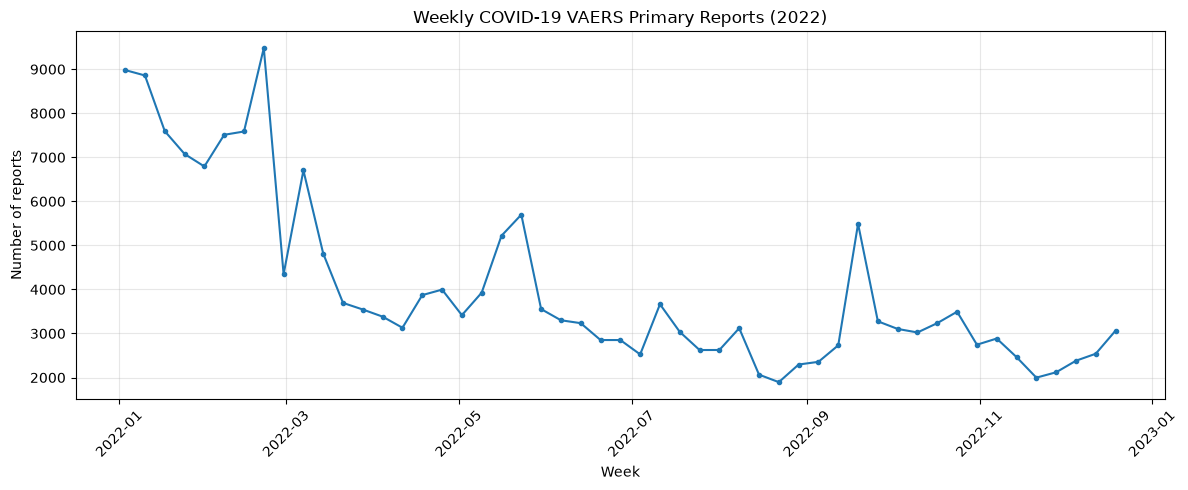

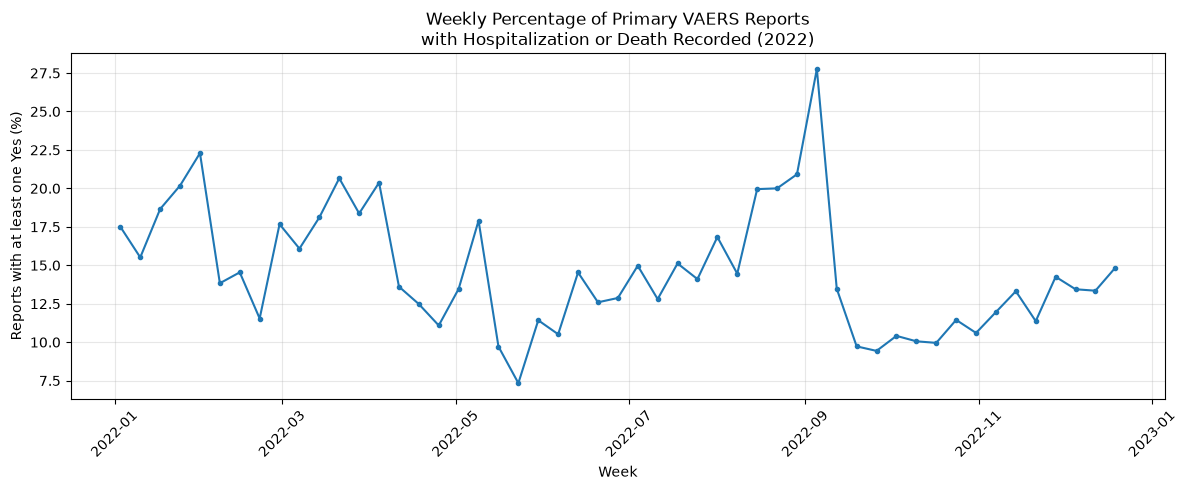

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# STEP 6: Select primary reports
primary = df[
    pd.to_numeric(df["ORDER"], errors="coerce") == 1
].copy()

print("Primary report rows:", len(primary))
print("Unique primary IDs:", primary["VAERS_ID"].nunique())
print("Duplicate primary IDs:",
      primary["VAERS_ID"].duplicated().sum())

assert primary["VAERS_ID"].is_unique, "Duplicate primary IDs found"

# Convert dates
primary["date"] = pd.to_datetime(
    primary["RECVDATE"],
    format="mixed",
    errors="raise"
)

# Create outcome indicators
primary["hospital_yes"] = (
    primary["HOSPITAL_STATUS"].eq("Yes").fillna(False)
)

primary["death_yes"] = (
    primary["DIED_STATUS"].eq("Yes").fillna(False)
)

primary["flag_yes"] = (
    primary["hospital_yes"] | primary["death_yes"]
)

# Assign each report to a Monday-starting week
primary["week"] = (
    primary["date"].dt.to_period("W-SUN").dt.start_time
)

# Aggregate weekly values
weekly_primary = primary.groupby("week").agg(
    total_reports=("VAERS_ID", "size"),
    hospital_yes=("hospital_yes", "sum"),
    death_yes=("death_yes", "sum"),
    any_yes=("flag_yes", "sum")
)

# Keep complete weeks only
weeks = pd.date_range(
    "2022-01-03", "2022-12-19", freq="W-MON"
)

weekly_primary = (
    weekly_primary.reindex(weeks, fill_value=0)
    .rename_axis("week")
    .reset_index()
)

weekly_primary["flag_percentage"] = (
    weekly_primary["any_yes"] /
    weekly_primary["total_reports"].replace(0, float("nan"))
) * 100

print("\nComplete weeks:", len(weekly_primary))
print("\nWeekly summary:")
print(weekly_primary.describe().round(2))

print("\nFirst five weeks:")
print(weekly_primary.head().to_string(index=False))

print("\nLast five weeks:")
print(weekly_primary.tail().to_string(index=False))

# GRAPH 1: Weekly report volume
plt.figure(figsize=(12, 5))
plt.plot(
    weekly_primary["week"],
    weekly_primary["total_reports"],
    marker="o",
    markersize=3
)
plt.title("Weekly COVID-19 VAERS Primary Reports (2022)")
plt.xlabel("Week")
plt.ylabel("Number of reports")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# GRAPH 2: Weekly flagged percentage
plt.figure(figsize=(12, 5))
plt.plot(
    weekly_primary["week"],
    weekly_primary["flag_percentage"],
    marker="o",
    markersize=3
)
plt.title(
    "Weekly Percentage of Primary VAERS Reports\n"
    "with Hospitalization or Death Recorded (2022)"
)
plt.xlabel("Week")
plt.ylabel("Reports with at least one Yes (%)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


C:\Users\USER\AppData\Local\Temp\ipykernel_1116\1266920449.py:24: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily["weekday"] = daily["date"].dt.dayofweek


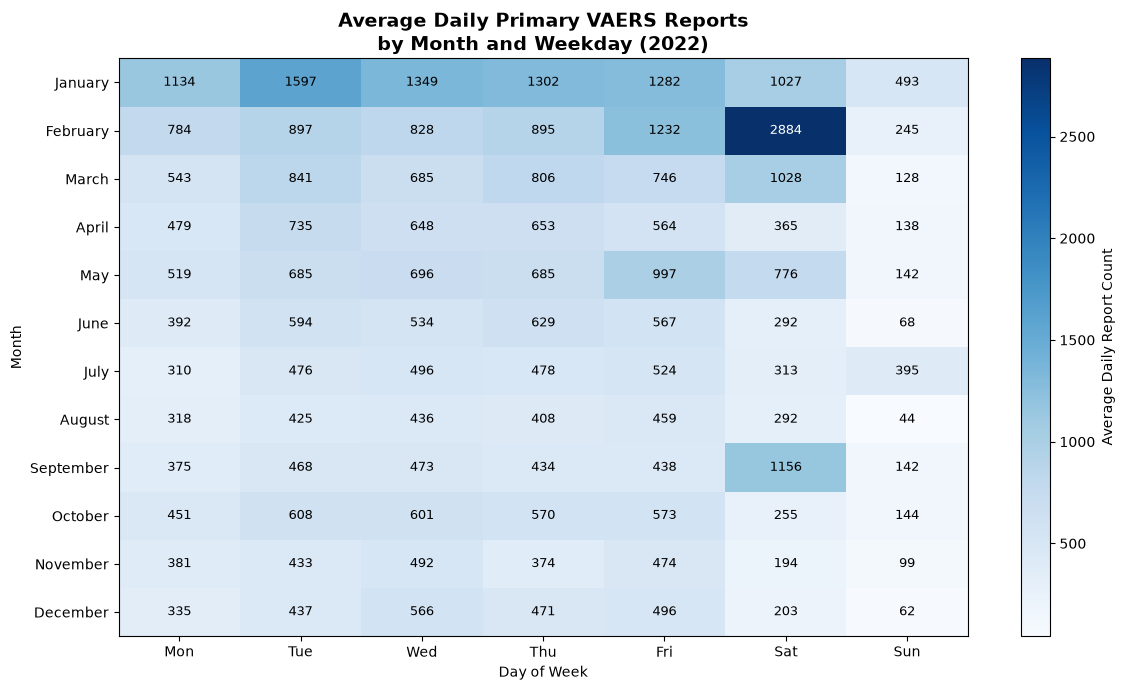

Heatmap created successfully!
Daily observations: 365
Saved: figures/month_weekday_heatmap.png


In [9]:

# STEP 7: Month x Weekday Reporting Heatmap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar
from pathlib import Path

# Daily primary-report counts, including zero-report dates
daily = (
    primary.set_index("date")
    .resample("D")
    .size()
    .reindex(
        pd.date_range("2022-01-01", "2022-12-31"),
        fill_value=0
    )
    .rename("total_reports")
    .rename_axis("date")
    .reset_index()
)

daily["month"] = daily["date"].dt.month
daily["weekday"] = daily["date"].dt.dayofweek

# Calculate average daily reports for each month and weekday
heatmap_data = daily.pivot_table(
    index="month",
    columns="weekday",
    values="total_reports",
    aggfunc="mean"
).reindex(
    index=range(1, 13),
    columns=range(7)
)

fig, ax = plt.subplots(figsize=(12, 7))

im = ax.imshow(
    heatmap_data.values,
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks(range(7))
ax.set_xticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

ax.set_yticks(range(12))
ax.set_yticklabels(
    [calendar.month_name[i] for i in range(1, 13)]
)

for i in range(12):
    for j in range(7):
        value = heatmap_data.iloc[i, j]
        ax.text(
            j, i, f"{value:.0f}",
            ha="center",
            va="center",
            color="white" if value > heatmap_data.values.max() * 0.6 else "black",
            fontsize=9
        )

ax.set_title(
    "Average Daily Primary VAERS Reports\n"
    "by Month and Weekday (2022)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Day of Week")
ax.set_ylabel("Month")

fig.colorbar(
    im, ax=ax,
    label="Average Daily Report Count"
)

plt.tight_layout()

# Save a publication-quality image
Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/month_weekday_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap created successfully!")
print("Daily observations:", len(daily))
print("Saved: figures/month_weekday_heatmap.png")


In [10]:

# STEP 8: Investigate reporting spikes

print("Top 15 highest reporting days:")
print(
    daily.nlargest(15, "total_reports")[
        ["date", "total_reports"]
    ].to_string(index=False)
)

print("\nFebruary Saturdays:")
feb_sat = daily[
    (daily["date"].dt.month == 2) &
    (daily["date"].dt.dayofweek == 5)
]
print(feb_sat.to_string(index=False))

print("\nSeptember Saturdays:")
sep_sat = daily[
    (daily["date"].dt.month == 9) &
    (daily["date"].dt.dayofweek == 5)
]
print(sep_sat.to_string(index=False))

print("\nData verification:")
print("Total daily reports:", daily["total_reports"].sum())
print("Primary report rows:", len(primary))
print(
    "Totals match:",
    daily["total_reports"].sum() == len(primary)
)

# Verify receipt-date format
us_dates = pd.to_datetime(
    primary["RECVDATE"].str.strip(),
    format="%m/%d/%Y",
    errors="coerce"
)

print("Dates failing US MM/DD/YYYY format:",
      us_dates.isna().sum())

print("Dates differing from existing parsing:",
      (us_dates.notna() &
       us_dates.ne(primary["date"])).sum())


Top 15 highest reporting days:
      date  total_reports
2022-02-26           5140
2022-09-24           2863
2022-02-19           2431
2022-03-12           2253
2022-02-12           2138
2022-01-08           1994
2022-02-05           1827
2022-01-11           1813
2022-01-12           1728
2022-01-14           1724
2022-05-28           1691
2022-01-04           1545
2022-01-18           1519
2022-01-25           1511
2022-05-20           1465

February Saturdays:
      date  total_reports  month  weekday
2022-02-05           1827      2        5
2022-02-12           2138      2        5
2022-02-19           2431      2        5
2022-02-26           5140      2        5

September Saturdays:
      date  total_reports  month  weekday
2022-09-03            258      9        5
2022-09-10            587      9        5
2022-09-17            917      9        5
2022-09-24           2863      9        5

Data verification:
Total daily reports: 210494
Primary report rows: 210494
Totals match: 

C:\Users\USER\AppData\Local\Temp\ipykernel_1116\44031266.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  (daily["date"].dt.dayofweek == 5)
C:\Users\USER\AppData\Local\Temp\ipykernel_1116\44031266.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  (daily["date"].dt.dayofweek == 5)


Training weeks: 41
Testing weeks: 10
Training period: 2022-01-03 to 2022-10-10
Testing period: 2022-10-17 to 2022-12-19

--- ADF TEST ---
ADF Statistic: -3.3064
P-value: 0.014594
Lags used: 0

Critical values:
1% : -3.6056
5% : -2.9371
10% : -2.607

Reject the unit-root null hypothesis.


C:\Users\USER\AppData\Local\Temp\ipykernel_1116\4073245398.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train, autolag="AIC")


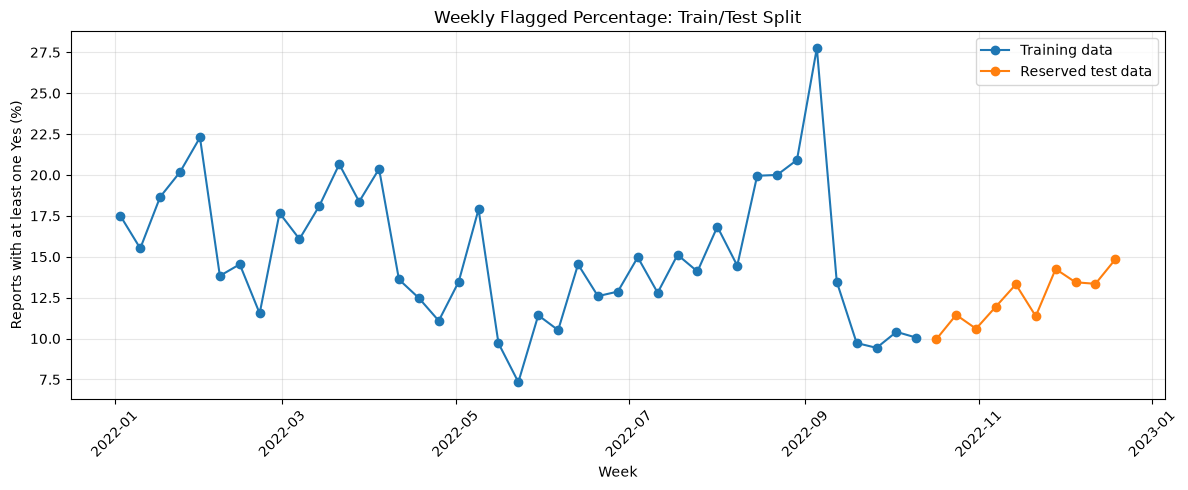

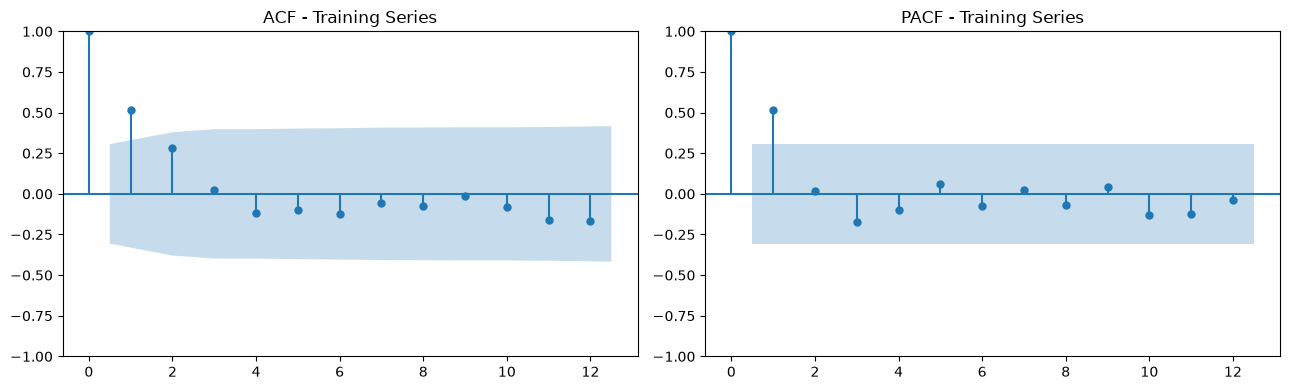


Step 9 completed.


In [11]:

# STEP 9: Stationarity, ACF and PACF

import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Select our primary time-series target
series = weekly_primary.set_index("week")[
    "flag_percentage"
].astype(float)

assert len(series) == 51, "Expected 51 complete weeks"
assert series.notna().all(), "Missing weekly percentages"

# Reserve the final 10 weeks for testing
train = series.iloc[:41]
test = series.iloc[41:]

print("Training weeks:", len(train))
print("Testing weeks:", len(test))

print("Training period:", train.index.min().date(),
      "to", train.index.max().date())

print("Testing period:", test.index.min().date(),
      "to", test.index.max().date())

# ADF stationarity test: training data only
adf_result = adfuller(train, autolag="AIC")

print("\n--- ADF TEST ---")
print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 6))
print("Lags used:", adf_result[2])

print("\nCritical values:")
for key, value in adf_result[4].items():
    print(key, ":", round(value, 4))

if adf_result[1] < 0.05:
    print("\nReject the unit-root null hypothesis.")
else:
    print("\nInsufficient evidence to reject the unit-root null.")

# Plot 1: Training and testing periods
plt.figure(figsize=(12, 5))

plt.plot(train.index, train.values,
         label="Training data", marker="o")

plt.plot(test.index, test.values,
         label="Reserved test data", marker="o")

plt.title("Weekly Flagged Percentage: Train/Test Split")
plt.xlabel("Week")
plt.ylabel("Reports with at least one Yes (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Autocorrelation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plot_acf(train, lags=12, ax=axes[0])
axes[0].set_title("ACF - Training Series")

plot_pacf(
    train,
    lags=12,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF - Training Series")

plt.tight_layout()
plt.show()

print("\nStep 9 completed.")


In [12]:

# Confirm ADF stationarity results

from statsmodels.tsa.stattools import adfuller

result = adfuller(
    train,
    autolag="AIC",
    result_object=False
)

print("ADF Statistic:", round(result[0], 4))
print("P-value:", round(result[1], 6))
print("Lags Used:", result[2])

if result[1] < 0.05:
    print("Evidence against a unit root (stationary candidate).")
else:
    print("Cannot reject the unit-root hypothesis.")


ADF Statistic: -3.3064
P-value: 0.014594
Lags Used: 0
Evidence against a unit root (stationary candidate).


Training weeks: 41
Testing weeks: 10


c:\Users\USER\OneDrive - NSBM\Documents\Stat\COVID-19_stat\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\USER\OneDrive - NSBM\Documents\Stat\COVID-19_stat\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\USER\OneDrive - NSBM\Documents\Stat\COVID-19_stat\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\USER\OneDrive - NSBM\Documents\Stat\COVID-19_stat\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\U


--- MODEL COMPARISON ---
                 Model    MAE   RMSE
Previous-week Baseline 1.2389 1.4715
          ARIMA(1,0,0) 1.2974 1.5549

--- FORECAST RESULTS ---
            actual  baseline  arima_100
week                                   
2022-10-17   9.954    10.056     12.444
2022-10-24  11.448     9.954     12.247
2022-10-31  10.601    11.448     13.025
2022-11-07  11.958    10.601     12.460
2022-11-14  13.312    11.958     13.203
2022-11-21  11.367    13.312     13.969
2022-11-28  14.252    11.367     12.804
2022-12-05  13.440    14.252     14.475
2022-12-12  13.346    13.440     13.997
2022-12-19  14.845    13.346     13.931

The baseline has equal or lower MAE.
The baseline has equal or lower RMSE.


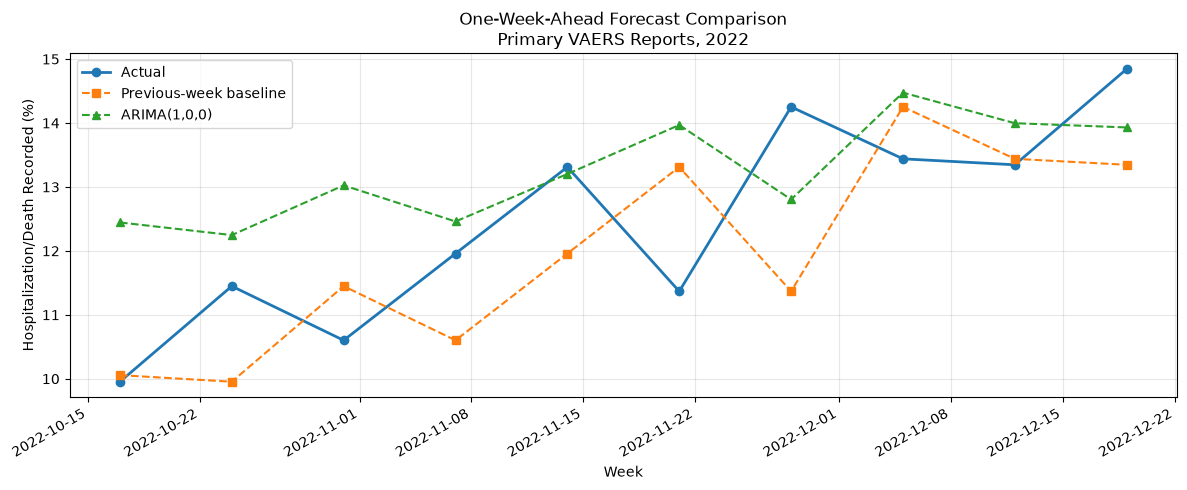


Step 10 completed successfully!


In [13]:

# STEP 10: Baseline vs ARIMA(1,0,0)
# Rolling one-week-ahead forecasting

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA

# 1. Prepare the time series
series = (
    weekly_primary
    .set_index("week")["flag_percentage"]
    .astype(float)
    .sort_index()
)

assert len(series) == 51
assert series.notna().all()
assert series.index.is_unique

train = series.iloc[:41].copy()
test = series.iloc[41:].copy()

print("Training weeks:", len(train))
print("Testing weeks:", len(test))

# 2. Rolling forecasts
history = train.copy()
results = []

for week, actual in test.items():

    # Model 1: Previous-week baseline
    baseline_prediction = float(history.iloc[-1])

    # Model 2: ARIMA(1,0,0)
    model = ARIMA(
        history,
        order=(1, 0, 0),
        trend="c"
    )

    fitted_model = model.fit()

    arima_prediction = float(
        fitted_model.forecast(steps=1).iloc[0]
    )

    # Store one-week-ahead predictions
    results.append({
        "week": week,
        "actual": float(actual),
        "baseline": baseline_prediction,
        "arima_100": arima_prediction
    })

    # Update history AFTER predicting this week
    history = pd.concat([
        history,
        pd.Series([float(actual)], index=[week])
    ])

forecast_results = pd.DataFrame(results)
forecast_results = forecast_results.set_index("week")

# 3. Evaluate models
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    return mae, rmse

baseline_mae, baseline_rmse = calculate_metrics(
    forecast_results["actual"],
    forecast_results["baseline"]
)

arima_mae, arima_rmse = calculate_metrics(
    forecast_results["actual"],
    forecast_results["arima_100"]
)

comparison = pd.DataFrame({
    "Model": ["Previous-week Baseline", "ARIMA(1,0,0)"],
    "MAE": [baseline_mae, arima_mae],
    "RMSE": [baseline_rmse, arima_rmse]
})

print("\n--- MODEL COMPARISON ---")
print(comparison.round(4).to_string(index=False))

print("\n--- FORECAST RESULTS ---")
print(forecast_results.round(3).to_string())

if arima_mae < baseline_mae:
    print("\nARIMA has lower MAE than the baseline.")
else:
    print("\nThe baseline has equal or lower MAE.")

if arima_rmse < baseline_rmse:
    print("ARIMA has lower RMSE than the baseline.")
else:
    print("The baseline has equal or lower RMSE.")

# 4. Plot actual versus predicted
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    forecast_results.index,
    forecast_results["actual"],
    marker="o",
    linewidth=2,
    label="Actual"
)

ax.plot(
    forecast_results.index,
    forecast_results["baseline"],
    marker="s",
    linestyle="--",
    label="Previous-week baseline"
)

ax.plot(
    forecast_results.index,
    forecast_results["arima_100"],
    marker="^",
    linestyle="--",
    label="ARIMA(1,0,0)"
)

ax.set_title(
    "One-Week-Ahead Forecast Comparison\n"
    "Primary VAERS Reports, 2022"
)

ax.set_xlabel("Week")
ax.set_ylabel("Hospitalization/Death Recorded (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/arima_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nStep 10 completed successfully!")


In [14]:
series = (
    weekly_primary
    .set_index("week")["flag_percentage"]
    .astype(float)
    .sort_index()
    .asfreq("W-MON")
)

ARIMA training model summary:
                               SARIMAX Results                                
Dep. Variable:        flag_percentage   No. Observations:                   41
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -110.622
Date:                Sat, 21 Nov 2026   AIC                            227.244
Time:                        00:21:19   BIC                            232.385
Sample:                    01-03-2022   HQIC                           229.116
                         - 10-10-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.1182      1.379     10.964      0.000      12.416      17.821
ar.L1          0.5282      0.109      4.840      0.000       0.314       0.742
sigma2        12.8110 

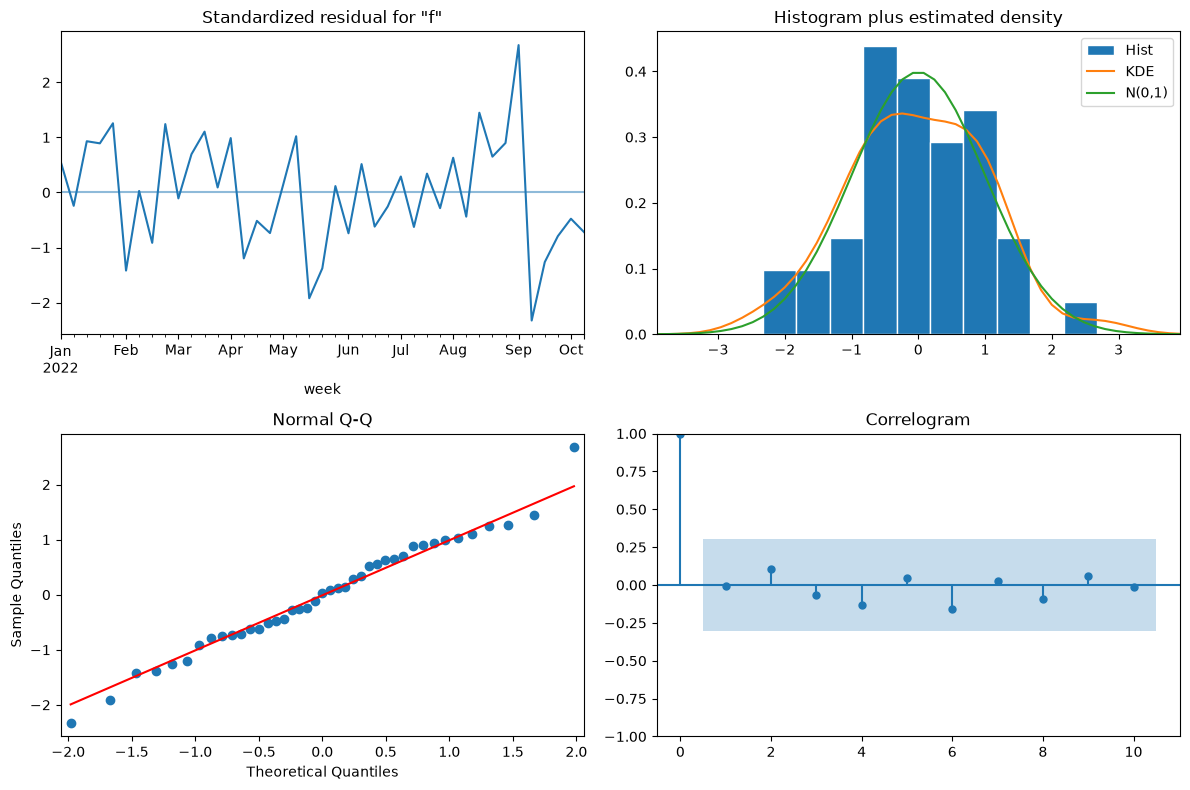


Prediction interval results:
            actual  predicted  lower   upper
week                                        
2022-10-17   9.954     12.444  5.429  19.460
2022-10-24  11.448     12.247  5.279  19.215
2022-10-31  10.601     13.025  6.135  19.914
2022-11-07  11.958     12.460  5.615  19.305
2022-11-14  13.312     13.203  6.433  19.973
2022-11-21  11.367     13.969  7.273  20.665
2022-11-28  14.252     12.804  6.139  19.469
2022-12-05  13.440     14.475  7.867  21.083
2022-12-12  13.346     13.997  7.451  20.543
2022-12-19  14.845     13.931  7.448  20.413

95% interval coverage: 100.0 %
Average interval width: 13.497 percentage points


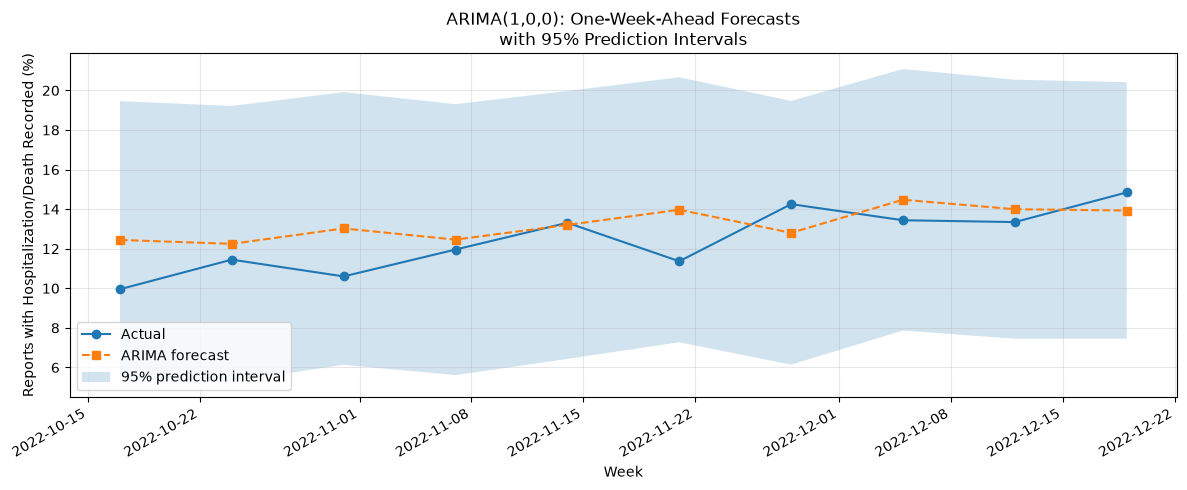


Step 11 completed!


In [15]:

# STEP 11: ARIMA diagnostics and prediction intervals

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

series = (
    weekly_primary.set_index("week")["flag_percentage"]
    .astype(float)
    .sort_index()
    .asfreq("W-MON")
)

train = series.iloc[:41]
test = series.iloc[41:]

# 1. Fit ARIMA using training data only
fitted_train = ARIMA(
    train, order=(1, 0, 0), trend="c"
).fit()

print("ARIMA training model summary:")
print(fitted_train.summary())

# 2. Residual autocorrelation test
lb = acorr_ljungbox(
    fitted_train.resid,
    lags=[5, 10],
    return_df=True
)

print("\nLjung-Box residual test:")
print(lb)

# 3. Residual diagnostic graphs
fitted_train.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

# 4. Rolling one-week-ahead prediction intervals
history = train.copy()
records = []

for week, actual in test.items():

    fitted = ARIMA(
        history,
        order=(1, 0, 0),
        trend="c"
    ).fit()

    prediction = fitted.get_forecast(steps=1)

    predicted = float(
        prediction.predicted_mean.iloc[0]
    )

    ci = prediction.conf_int(alpha=0.05)

    lower = float(ci.iloc[0, 0])
    upper = float(ci.iloc[0, 1])

    records.append({
        "week": week,
        "actual": float(actual),
        "predicted": predicted,
        "lower": lower,
        "upper": upper
    })

    # Actual observation becomes available after forecasting
    history = pd.concat([
        history,
        pd.Series([float(actual)], index=[week])
    ]).asfreq("W-MON")

intervals = pd.DataFrame(records).set_index("week")

# 5. Interval evaluation
covered = (
    (intervals["actual"] >= intervals["lower"]) &
    (intervals["actual"] <= intervals["upper"])
)

coverage = covered.mean() * 100
average_width = (
    intervals["upper"] - intervals["lower"]
).mean()

print("\nPrediction interval results:")
print(intervals.round(3).to_string())

print("\n95% interval coverage:", round(coverage, 2), "%")
print("Average interval width:",
      round(average_width, 3), "percentage points")

# 6. Forecast graph with uncertainty bands
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    intervals.index,
    intervals["actual"],
    marker="o",
    label="Actual"
)

ax.plot(
    intervals.index,
    intervals["predicted"],
    linestyle="--",
    marker="s",
    label="ARIMA forecast"
)

ax.fill_between(
    intervals.index,
    intervals["lower"],
    intervals["upper"],
    alpha=0.2,
    label="95% prediction interval"
)

ax.set_title(
    "ARIMA(1,0,0): One-Week-Ahead Forecasts\n"
    "with 95% Prediction Intervals"
)

ax.set_xlabel("Week")
ax.set_ylabel("Reports with Hospitalization/Death Recorded (%)")
ax.grid(alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/arima_prediction_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nStep 11 completed!")


In [16]:

# STEP 12: Check manufacturer data before creating the heatmap

import pandas as pd

manufacturer_data = pd.read_csv(
    INPUT,
    usecols=[
        "VAERS_ID",
        "ORDER",
        "RECVDATE",
        "COVID_MANUFACTURERS"
    ],
    dtype="string",
    encoding="utf-8-sig"
)

# Keep primary reports only
manufacturer_data = manufacturer_data[
    pd.to_numeric(
        manufacturer_data["ORDER"],
        errors="coerce"
    ) == 1
].copy()

print("Primary manufacturer rows:", len(manufacturer_data))

print("\nMissing manufacturer values:")
print(
    manufacturer_data["COVID_MANUFACTURERS"]
    .isna().sum()
)

print("\nTop 20 manufacturer values:")
print(
    manufacturer_data["COVID_MANUFACTURERS"]
    .value_counts(dropna=False)
    .head(20)
    .to_string()
)

print("\nDistinct manufacturer values:")
print(
    manufacturer_data["COVID_MANUFACTURERS"]
    .nunique(dropna=False)
)

print("\nUnique report IDs:")
print(manufacturer_data["VAERS_ID"].nunique())


Primary manufacturer rows: 210494

Missing manufacturer values:
0

Top 20 manufacturer values:
COVID_MANUFACTURERS
["PFIZER\\BIONTECH"]                                     107681
["MODERNA"]                                               89142
["JANSSEN"]                                                8533
["PFIZER\\BIONTECH","UNKNOWN MANUFACTURER"]                2621
["MODERNA","PFIZER\\BIONTECH"]                              941
["UNKNOWN MANUFACTURER"]                                    680
["JANSSEN","MODERNA"]                                       368
["JANSSEN","PFIZER\\BIONTECH"]                              225
["NOVAVAX"]                                                 197
["JANSSEN","MODERNA","PFIZER\\BIONTECH"]                     35
["MODERNA","UNKNOWN MANUFACTURER"]                           27
["UNKNOWN MANUFACTURER","PFIZER\\BIONTECH"]                  13
["MODERNA","PFIZER\\BIONTECH","UNKNOWN MANUFACTURER"]        11
["JANSSEN","UNKNOWN MANUFACTURER"]                   

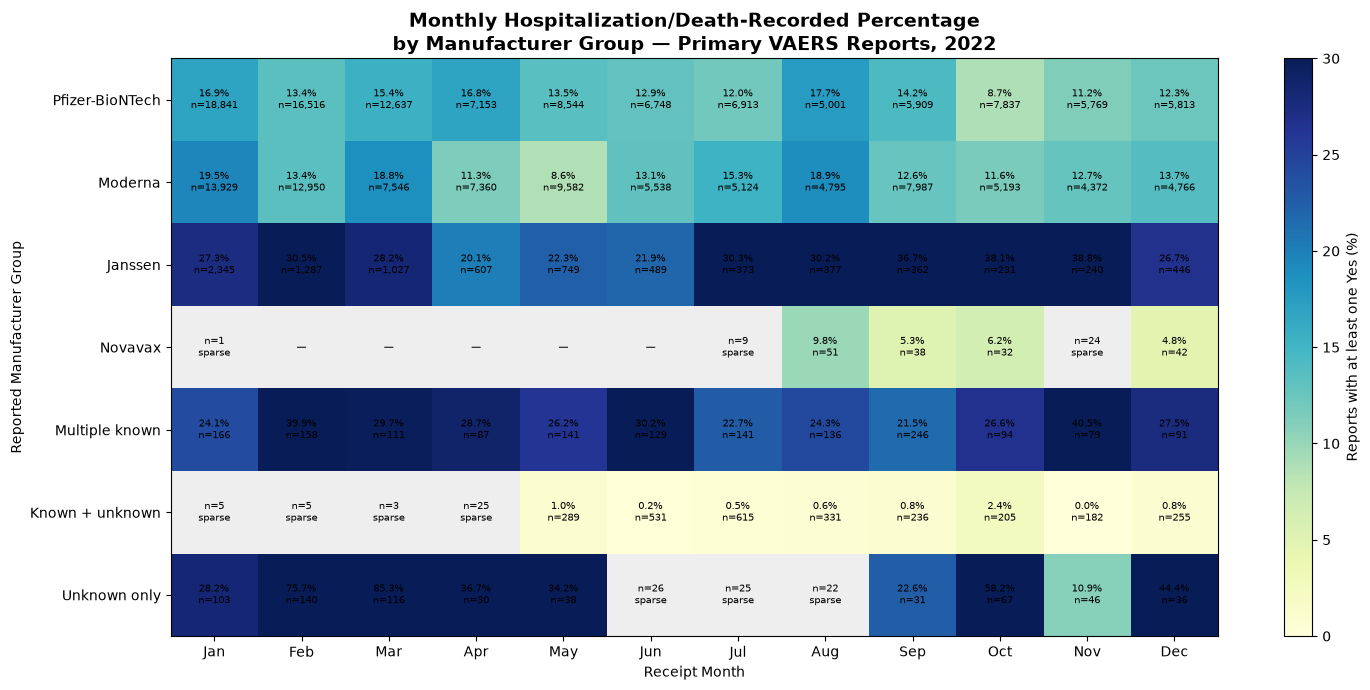


Manufacturer group counts:
manufacturer_group
Pfizer-BioNTech    107681
Moderna             89142
Janssen              8533
Known + unknown      2682
Multiple known       1579
Unknown only          680
Novavax               197

Total reports: 210494
Sparse cells: 10
Step 13 completed!


In [17]:

# STEP 13: Manufacturer x Month Heatmap

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Recognized manufacturer labels
known = {
    "PFIZER\\BIONTECH": "Pfizer-BioNTech",
    "MODERNA": "Moderna",
    "JANSSEN": "Janssen",
    "NOVAVAX": "Novavax"
}

# Parse JSON manufacturer lists
def classify_manufacturer(value):
    if pd.isna(value):
        return "Unknown only"

    items = json.loads(value)

    if not isinstance(items, list):
        raise ValueError(f"Expected list: {value}")

    items = set(
        str(item).strip().upper()
        for item in items
    )

    if len(items) == 1:
        item = next(iter(items))

        if item in known:
            return known[item]

        if item == "UNKNOWN MANUFACTURER":
            return "Unknown only"

    if items and items.issubset(set(known)):
        return "Multiple known"

    if (
        "UNKNOWN MANUFACTURER" in items
        and any(item in known for item in items)
        and items.issubset(
            set(known) | {"UNKNOWN MANUFACTURER"}
        )
    ):
        return "Known + unknown"

    return "Other / unclassified"

data = manufacturer_data.copy()

data["manufacturer_group"] = (
    data["COVID_MANUFACTURERS"]
    .map(classify_manufacturer)
)

# Attach outcome indicator from primary reports
data = data.merge(
    primary[["VAERS_ID", "flag_yes"]],
    on="VAERS_ID",
    how="left",
    validate="one_to_one"
)

assert len(data) == len(primary)
assert data["flag_yes"].notna().all()

data["date"] = pd.to_datetime(
    data["RECVDATE"],
    format="%m/%d/%Y",
    errors="raise"
)

data["month"] = data["date"].dt.month

# Group monthly results
monthly = data.groupby(
    ["manufacturer_group", "month"]
).agg(
    n=("VAERS_ID", "size"),
    flagged=("flag_yes", "sum")
).reset_index()

monthly["percentage"] = (
    100 * monthly["flagged"] / monthly["n"]
)

group_order = [
    "Pfizer-BioNTech",
    "Moderna",
    "Janssen",
    "Novavax",
    "Multiple known",
    "Known + unknown",
    "Unknown only",
    "Other / unclassified"
]

# Create monthly percentage and count matrices
percentages = monthly.pivot(
    index="manufacturer_group",
    columns="month",
    values="percentage"
).reindex(index=group_order, columns=range(1, 13))

counts = monthly.pivot(
    index="manufacturer_group",
    columns="month",
    values="n"
).reindex(index=group_order, columns=range(1, 13))

counts = counts.fillna(0).astype(int)

# Exclude absent categories
keep = counts.sum(axis=1) > 0
counts = counts.loc[keep]
percentages = percentages.loc[keep]

# Mask sparse cells: fewer than 30 reports
minimum_n = 30
masked = percentages.mask(counts < minimum_n)

fig, ax = plt.subplots(figsize=(15, 7))

cmap = plt.colormaps["YlGnBu"].copy()
cmap.set_bad("#eeeeee")

im = ax.imshow(
    masked.to_numpy(dtype=float),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=30
)

ax.set_xticks(range(12))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
])

ax.set_yticks(range(len(counts)))
ax.set_yticklabels(counts.index)

for i in range(len(counts)):
    for j in range(12):
        n = counts.iloc[i, j]
        pct = percentages.iloc[i, j]

        if n == 0:
            label = "—"
        elif n < minimum_n:
            label = f"n={n}\nsparse"
        else:
            label = f"{pct:.1f}%\nn={n:,}"

        ax.text(
            j, i, label,
            ha="center",
            va="center",
            fontsize=7
        )

ax.set_title(
    "Monthly Hospitalization/Death-Recorded Percentage\n"
    "by Manufacturer Group — Primary VAERS Reports, 2022",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Receipt Month")
ax.set_ylabel("Reported Manufacturer Group")

fig.colorbar(
    im, ax=ax,
    label="Reports with at least one Yes (%)"
)

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/manufacturer_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nManufacturer group counts:")
print(
    data["manufacturer_group"]
    .value_counts()
    .to_string()
)

print("\nTotal reports:", len(data))
print("Sparse cells:", (counts.gt(0) & counts.lt(30)).sum().sum())
print("Step 13 completed!")


REPORTING SPIKE ANALYSIS
             total_reports  flagged_reports  flag_percentage
receipt_day                                                 
2022-02-26            5140               96            1.868
2022-09-24            2863              157            5.484

AFFECTED WEEKS
            total_reports  flag_percentage  adjusted_total  adjusted_flagged  adjusted_percentage  percentage_change_pp
week                                                                                                                   
2022-02-21           9481           11.539            4341               998                22.99                11.451
2022-09-19           5490            9.727            2627               377               14.351                 4.624

TOP FIVE ORIGINAL FLAGGED WEEKS
      week  total_reports  flag_percentage
2022-09-05           2356        27.758913
2022-01-31           6792        22.290931
2022-08-29           2295        20.915033
2022-03-21           3694     

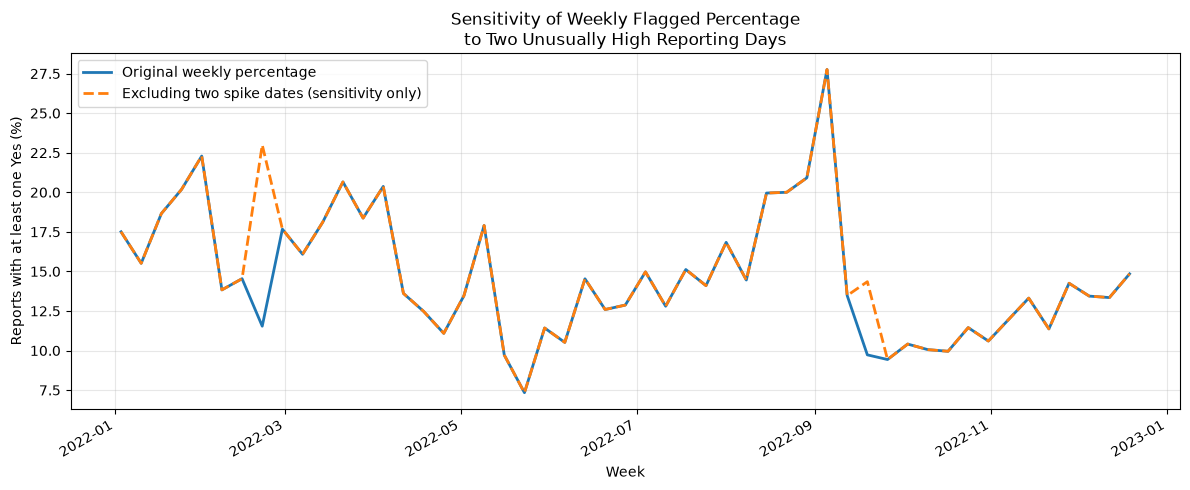


Step 14 completed successfully!


In [18]:

# STEP 14: Reporting Spike Sensitivity Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

analysis = primary.copy()

analysis["receipt_day"] = analysis["date"].dt.normalize()

# Previously identified unusual reporting dates
spike_dates = pd.to_datetime([
    "2022-02-26",
    "2022-09-24"
])

# 1. Investigate these dates
spike_reports = analysis[
    analysis["receipt_day"].isin(spike_dates)
]

spike_summary = spike_reports.groupby("receipt_day").agg(
    total_reports=("VAERS_ID", "size"),
    flagged_reports=("flag_yes", "sum")
)

spike_summary["flag_percentage"] = (
    100 * spike_summary["flagged_reports"]
    / spike_summary["total_reports"]
)

print("REPORTING SPIKE ANALYSIS")
print(spike_summary.round(3).to_string())

# 2. Sensitivity analysis only:
# Exclude the identified days from a separate copy
adjusted = analysis[
    ~analysis["receipt_day"].isin(spike_dates)
].copy()

adjusted_weekly = adjusted.groupby("week").agg(
    adjusted_total=("VAERS_ID", "size"),
    adjusted_flagged=("flag_yes", "sum")
)

adjusted_weekly = adjusted_weekly.reindex(
    pd.DatetimeIndex(weekly_primary["week"]),
    fill_value=0
)

adjusted_weekly["adjusted_percentage"] = (
    100 * adjusted_weekly["adjusted_flagged"]
    / adjusted_weekly["adjusted_total"].replace(0, np.nan)
)

# 3. Compare original versus adjusted weeks
comparison_spikes = (
    weekly_primary.set_index("week")[
        ["total_reports", "flag_percentage"]
    ].join(adjusted_weekly)
)

comparison_spikes["percentage_change_pp"] = (
    comparison_spikes["adjusted_percentage"]
    - comparison_spikes["flag_percentage"]
)

affected_weeks = comparison_spikes[
    comparison_spikes["total_reports"]
    != comparison_spikes["adjusted_total"]
]

print("\nAFFECTED WEEKS")
print(affected_weeks.round(3).to_string())

print("\nTOP FIVE ORIGINAL FLAGGED WEEKS")
print(
    weekly_primary.nlargest(
        5, "flag_percentage"
    )[["week", "total_reports", "flag_percentage"]]
    .to_string(index=False)
)

# 4. Visualization
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    comparison_spikes.index,
    comparison_spikes["flag_percentage"],
    label="Original weekly percentage",
    linewidth=2
)

ax.plot(
    comparison_spikes.index,
    comparison_spikes["adjusted_percentage"],
    label="Excluding two spike dates (sensitivity only)",
    linestyle="--",
    linewidth=2
)

ax.set_title(
    "Sensitivity of Weekly Flagged Percentage\n"
    "to Two Unusually High Reporting Days"
)

ax.set_xlabel("Week")
ax.set_ylabel("Reports with at least one Yes (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/spike_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nStep 14 completed successfully!")


In [20]:

# STEP 15: Investigate reporting spike composition

import numpy as np
import pandas as pd

# 'data' is the manufacturer dataset from Step 13
audit = data[
    ["VAERS_ID", "date", "manufacturer_group", "flag_yes"]
].copy()

audit["week"] = (
    audit["date"].dt.to_period("W-SUN").dt.start_time
)

spike_dates = pd.to_datetime([
    "2022-02-26",
    "2022-09-24"
])

for spike_date in spike_dates:

    week_start = spike_date.to_period("W-SUN").start_time

    subset = audit[
        audit["week"] == week_start
    ].copy()

    subset["period"] = np.where(
        subset["date"] == spike_date,
        "Spike date",
        "Other days"
    )

    print("\n" + "=" * 55)
    print("SPIKE DATE:", spike_date.date())
    print("=" * 55)

    summary = subset.groupby("period").agg(
        reports=("VAERS_ID", "size"),
        flagged=("flag_yes", "sum")
    )

    summary["flag_percentage"] = (
        100 * summary["flagged"] / summary["reports"]
    )

    print("\nReport summary:")
    print(summary.round(2).to_string())

    manufacturer = subset.groupby(
        ["period", "manufacturer_group"]
    ).agg(
        reports=("VAERS_ID", "size"),
        flagged=("flag_yes", "sum")
    )

    manufacturer["share_pct"] = (
        manufacturer["reports"]
        / manufacturer.groupby(level=0)["reports"].transform("sum")
        * 100
    )

    manufacturer["flag_pct"] = (
        manufacturer["flagged"]
        / manufacturer["reports"]
        * 100
    )

    print("\nManufacturer composition:")
    print(manufacturer.round(2).to_string())

print("\nStep 15 completed!")



SPIKE DATE: 2022-02-26

Report summary:
            reports  flagged  flag_percentage
period                                       
Other days     4341      998            22.99
Spike date     5140       96             1.87

Manufacturer composition:
                               reports  flagged  share_pct  flag_pct
period     manufacturer_group                                       
Other days Janssen                 191       82       4.40     42.93
           Known + unknown           1        0       0.02       0.0
           Moderna                1734      353      39.94     20.36
           Multiple known           21       12       0.48     57.14
           Pfizer-BioNTech        2314      479      53.31      20.7
           Unknown only             80       72       1.84      90.0
Spike date Janssen                  82       19       1.60     23.17
           Known + unknown           3        0       0.06       0.0
           Moderna                4203       37      81.77

FORECAST SENSITIVITY COMPARISON
                  Model    MAE   RMSE
 Previous-week baseline 1.2389 1.4715
         Original ARIMA 1.2974 1.5549
Adjusted-training ARIMA 1.4392 1.7147


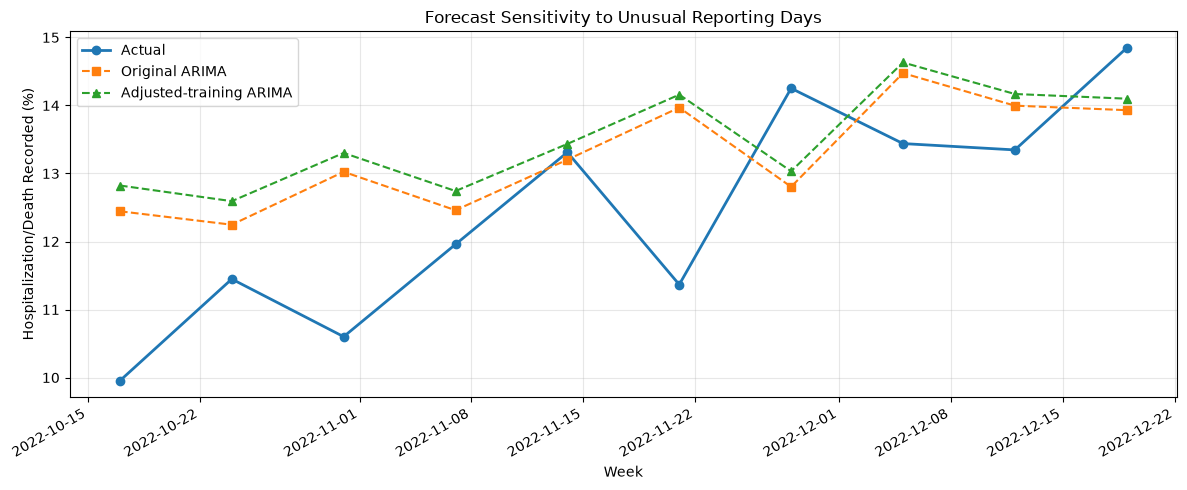

Step 16 completed!


In [21]:

# STEP 16: Forecast sensitivity analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from pathlib import Path

# Original weekly data
original = (
    weekly_primary
    .set_index("week")["flag_percentage"]
    .astype(float)
    .sort_index()
    .asfreq("W-MON")
)

# Exclude two unusual days in a separate copy
spike_dates = pd.to_datetime([
    "2022-02-26",
    "2022-09-24"
])

adjusted_rows = primary[
    ~primary["date"].dt.normalize().isin(spike_dates)
].copy()

adjusted_weekly = (
    adjusted_rows.groupby("week")
    .agg(
        total=("VAERS_ID", "size"),
        flagged=("flag_yes", "sum")
    )
    .reindex(original.index, fill_value=0)
)

adjusted_series = (
    100 * adjusted_weekly["flagged"]
    / adjusted_weekly["total"].replace(0, np.nan)
).asfreq("W-MON")

assert len(original) == 51
assert adjusted_series.notna().all()

# Keep the original test observations unchanged
test = original.iloc[41:]

assert np.allclose(
    adjusted_series.iloc[41:].values,
    test.values
)

def rolling_forecast(training_series, test_series):
    history = training_series.copy()
    predictions = []
    baseline_predictions = []

    for week, actual in test_series.items():

        baseline_predictions.append(
            float(history.iloc[-1])
        )

        fitted = ARIMA(
            history,
            order=(1, 0, 0),
            trend="c"
        ).fit()

        prediction = float(
            fitted.forecast(steps=1).iloc[0]
        )

        predictions.append(prediction)

        # Update only after making the forecast
        history.loc[week] = float(actual)
        history = history.asfreq("W-MON")

    return (
        np.array(predictions),
        np.array(baseline_predictions)
    )

# Original training data
original_pred, baseline_pred = rolling_forecast(
    original.iloc[:41],
    test
)

# Training data excluding the spike dates
adjusted_pred, adjusted_baseline = rolling_forecast(
    adjusted_series.iloc[:41],
    test
)

def metrics(actual, predicted):
    errors = np.asarray(actual) - np.asarray(predicted)

    return (
        np.mean(np.abs(errors)),
        np.sqrt(np.mean(errors ** 2))
    )

results = []

for name, predicted in [
    ("Previous-week baseline", baseline_pred),
    ("Original ARIMA", original_pred),
    ("Adjusted-training ARIMA", adjusted_pred)
]:
    mae, rmse = metrics(test.values, predicted)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results = pd.DataFrame(results)

print("FORECAST SENSITIVITY COMPARISON")
print(results.round(4).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    test.index, test.values,
    marker="o", linewidth=2,
    label="Actual"
)

ax.plot(
    test.index, original_pred,
    marker="s", linestyle="--",
    label="Original ARIMA"
)

ax.plot(
    test.index, adjusted_pred,
    marker="^", linestyle="--",
    label="Adjusted-training ARIMA"
)

ax.set_title(
    "Forecast Sensitivity to Unusual Reporting Days"
)

ax.set_xlabel("Week")
ax.set_ylabel("Hospitalization/Death Recorded (%)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/forecast_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Step 16 completed!")


In [22]:

# STEP 17: Export final time-series results

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Final weekly analysis dataset
weekly_primary.to_csv(
    output_dir / "weekly_primary.csv",
    index=False
)

# Ten-week forecast comparison
forecast_results.to_csv(
    output_dir / "forecast_results.csv"
)

# Final model comparison including sensitivity
results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# ARIMA prediction intervals
intervals.to_csv(
    output_dir / "prediction_intervals.csv"
)

# Reporting-spike sensitivity results
comparison_spikes.to_csv(
    output_dir / "spike_sensitivity.csv"
)

print("Final datasets exported successfully!")

for file in output_dir.glob("*.csv"):
    print(file.name)


Final datasets exported successfully!
forecast_results.csv
model_comparison.csv
prediction_intervals.csv
spike_sensitivity.csv
weekly_primary.csv


In [23]:

# STEP 18: Final reproducibility checks

from pathlib import Path
import pandas as pd

required_files = [
    "weekly_primary.csv",
    "forecast_results.csv",
    "model_comparison.csv",
    "prediction_intervals.csv",
    "spike_sensitivity.csv"
]

for name in required_files:
    path = Path("outputs") / name
    assert path.is_file(), f"Missing: {name}"
    print("Verified:", name)

saved_weekly = pd.read_csv(
    "outputs/weekly_primary.csv",
    parse_dates=["week"]
)

assert len(saved_weekly) == 51
assert saved_weekly["week"].is_unique
assert saved_weekly["total_reports"].gt(0).all()
assert saved_weekly["flag_percentage"].between(0, 100).all()

saved_forecasts = pd.read_csv(
    "outputs/forecast_results.csv"
)

assert len(saved_forecasts) == 10

print("\nAll final checks passed!")
print("Weekly observations:", len(saved_weekly))
print("Test forecasts:", len(saved_forecasts))


Verified: weekly_primary.csv
Verified: forecast_results.csv
Verified: model_comparison.csv
Verified: prediction_intervals.csv
Verified: spike_sensitivity.csv

All final checks passed!
Weekly observations: 51
Test forecasts: 10
